# Метод разделения переменных и численное интегрирование

**Задача 2.2** Определить численно решения и построить графики решений ОДУ
$$
\frac{dx}{dt}=f(kx),
\qquad
f(x)=\sin^2 x,\quad |\sin x|,\quad \sqrt{|\sin x|},\quad
\operatorname{sign}(\sin x)\sqrt{|\sin x|}.
$$
Каким образом следует выбирать и промежуток, и шаг интегрирования, чтобы набор кривых на графике дал полное представление о свойствах решений? Объясните свой выбор.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

%config InlineBackend.figure_format = 'retina'

# Постоянные
m = 2
k = 17

# Палитра
maroon     = [0.2078, 0.3608, 0.4902] # вещественная часть
red        = [0.7529, 0.4235, 0.5176] # мнимая часть
cream      = [0.8000, 0.8000, 0.8000] # серая сетка
background = [1.0000, 1.0000, 1.0000]

# Условное обозначение постоянных решений в легенде
equilibrium_handle = Line2D(
    [0], [0], color=cream, lw=0.9, ls='--', label=r'$x=j\pi/k$'
)

## Решение

Дифференциальное уравнение типа
$$
\frac{dx(t)}{dt}=f(x);\qquad f(x)\ne0
$$

можно решить методом разделения переменных. Поскольку выполняется неравенство, можно применить теорему об обратной функции:
$$
\frac{dt}{dx}=\frac1{f(x)}
$$

Интегрируя, получим решение:
$$
t+C=\int\frac{dx}{f(x)}.
$$

В нашем задании правая часть равна $f(kx)$. Подставляем её в ту же формулу:
$$
\frac{dt}{dx}=\frac1{f(kx)},\qquad t+C=\int\frac{dx}{f(kx)}.
$$

При заданном $x(0)=x_0$, на промежутке, где правая часть не равна нулю:
$$
t=\int_{x_0}^{x(t)}\frac{du}{f(ku)}.
$$

Эта формула даёт для четырёх уравнений:
$$
t=\int_{x_0}^{x(t)}\frac{du}{\sin^2(ku)},\qquad
 t=\int_{x_0}^{x(t)}\frac{du}{|\sin(ku)|},
$$
$$
t=\int_{x_0}^{x(t)}\frac{du}{\sqrt{|\sin(ku)|}},\qquad
 t=\int_{x_0}^{x(t)}\frac{du}{\operatorname{sign}(\sin(ku))\sqrt{|\sin(ku)|}}.
$$

##### Стационарные решения и направление движения

Во всех четырёх случаях правая часть равна нулю при
$$
\sin(kx)=0\quad\Longleftrightarrow\quad kx=j\pi,\quad j\in\mathbb Z.
$$

Значит, существуют постоянные решения
$$
\boxed{x(t)=\frac{j\pi}{k}.}
$$

Их нужно рассмотреть до разделения переменных: деление на правую часть исключило бы эти решения.

Для первых трёх функций правая часть положительна между соседними нулями. Поэтому непостоянное решение движется вправо: $x(t)$ возрастает. В четвёртом случае знак правой части чередуется. Между равновесиями имеем
$$
\frac{2j\pi}{k}<x<\frac{(2j+1)\pi}{k}\quad\Longrightarrow\quad \frac{dx}{dt}>0,
$$
а также
$$
\frac{(2j-1)\pi}{k}<x<\frac{2j\pi}{k}\quad\Longrightarrow\quad \frac{dx}{dt}<0.
$$

Следовательно, равновесия $x=(2j+1)\pi/k$ притягивают решения с обеих сторон, а равновесия $x=2j\pi/k$ отталкивают их с обеих сторон.

Меняем масштаб.
Чтобы одинаково выбирать сетки для четырёх уравнений, положим
$$
y=kx,\qquad \tau=kt.
$$
Тогда
$$
\frac{dy}{d\tau}=\frac{k\,dx}{k\,dt}=f(y),\qquad x=\frac yk,\quad t=\frac\tau k.
$$

Расстояние между соседними равновесиями в переменной $y$ равно $\pi$, а в исходной переменной $x$ равно $\pi/17\approx0.1848$.
Применяем метод разделения переменных
На промежутке, где $f(y)\ne0$, используем формулу со стр. 56 лекций:
$$
d\tau=\frac{dy}{f(y)},\qquad \tau-\tau_0=\int_{y_0}^{y}\frac{du}{f(u)}.
$$

Сначала вычисляем время как функцию положения, затем по возрастающей таблице находим положение как функцию времени.
Проверим, сколько времени нужно, чтобы дойти до нуля правой части. При малом $v$ имеем $\sin v\sim v$. Поэтому в окрестности равновесия $y=j\pi$: для $\sin^2y$ время определяется интегралом типа $\int dv/v^2$, который расходится у нуля; для $|\sin y|$ — интегралом типа $\int dv/|v|$, который также расходится; для двух функций с квадратным корнем — интегралом типа $\int dv/\sqrt{|v|}$. Он сходится, поскольку $\int_0^\varepsilon v^{-1/2}\,dv=2\sqrt\varepsilon$.

Следовательно, в первых двух уравнениях равновесие достигается только при бесконечном времени, а в последних двух возможно достижение за конечное время.

##### Первые два уравнения

При $j\pi<y<(j+1)\pi$ положим $r=y-j\pi$, $0<r<\pi$. Тогда

$$
\tau=\int_{r_0}^{r}\frac{du}{\sin^2u}
=\cot r_0-\cot r,
$$

$$
\tau=\int_{r_0}^{r}\frac{du}{\sin u}
=\ln\tan\frac r2-\ln\tan\frac{r_0}{2}.
$$

Эти формулы получены разделением переменных.

In [10]:
def regular_solution(tau, y0, power):
    j = int(np.floor(y0 / np.pi))
    r0 = y0 - j * np.pi

    if power == 2:
        r = np.arctan2(np.ones_like(tau), 1 / np.tan(r0) - tau)
    else:
        r = 2 * np.arctan(np.tan(r0 / 2) * np.exp(tau))

    return j * np.pi + r


def cumulative_integral(grid, values):
    areas = 0.5 * (values[:-1] + values[1:]) * np.diff(grid)
    return np.r_[0.0, np.cumsum(areas)]


def sqrt_table(intervals=4000):
    theta = np.linspace(0, np.pi, intervals + 1)
    r = 0.5 * np.pi * (1 - np.cos(theta))

    integrand = np.empty_like(theta)
    integrand[0] = integrand[-1] = np.sqrt(np.pi)
    distance = np.minimum(r[1:-1], np.pi - r[1:-1])
    integrand[1:-1] = 0.5 * np.pi * np.sin(theta[1:-1]) / np.sqrt(np.sin(distance))

    return r, cumulative_integral(theta, integrand)


r_sqrt, F_sqrt = sqrt_table()
L = F_sqrt[-1]


def sqrt_solution(tau, y0):
    j0 = int(np.floor(y0 / np.pi))
    r0 = y0 - j0 * np.pi
    q = j0 * L + np.interp(r0, r_sqrt, F_sqrt) + np.asarray(tau)
    j = np.floor(q / L).astype(int)
    local_time = q - j * L
    return j * np.pi + np.interp(local_time, F_sqrt, r_sqrt)


def signed_sqrt_solution(tau, y0):
    j = int(np.floor(y0 / np.pi))
    r0 = y0 - j * np.pi
    direction = 1 if j % 2 == 0 else -1
    q = np.interp(r0, r_sqrt, F_sqrt) + direction * np.asarray(tau)
    q = np.clip(q, 0, L)
    return j * np.pi + np.interp(q, F_sqrt, r_sqrt)

##### Промежуток и шаг

Берём

$$
-12\leq\tau\leq12,
\qquad
\Delta\tau=0.01.
$$

Тогда

$$
-\frac{12}{17}\leq t\leq\frac{12}{17},
\qquad
\Delta t=\frac{0.01}{17}.
$$

На каждом из трёх соседних промежутков между равновесиями берём начальные точки $0.15\pi$, $0.5\pi$, $0.85\pi$ от левой границы. Горизонтальные пунктирные линии — постоянные решения.

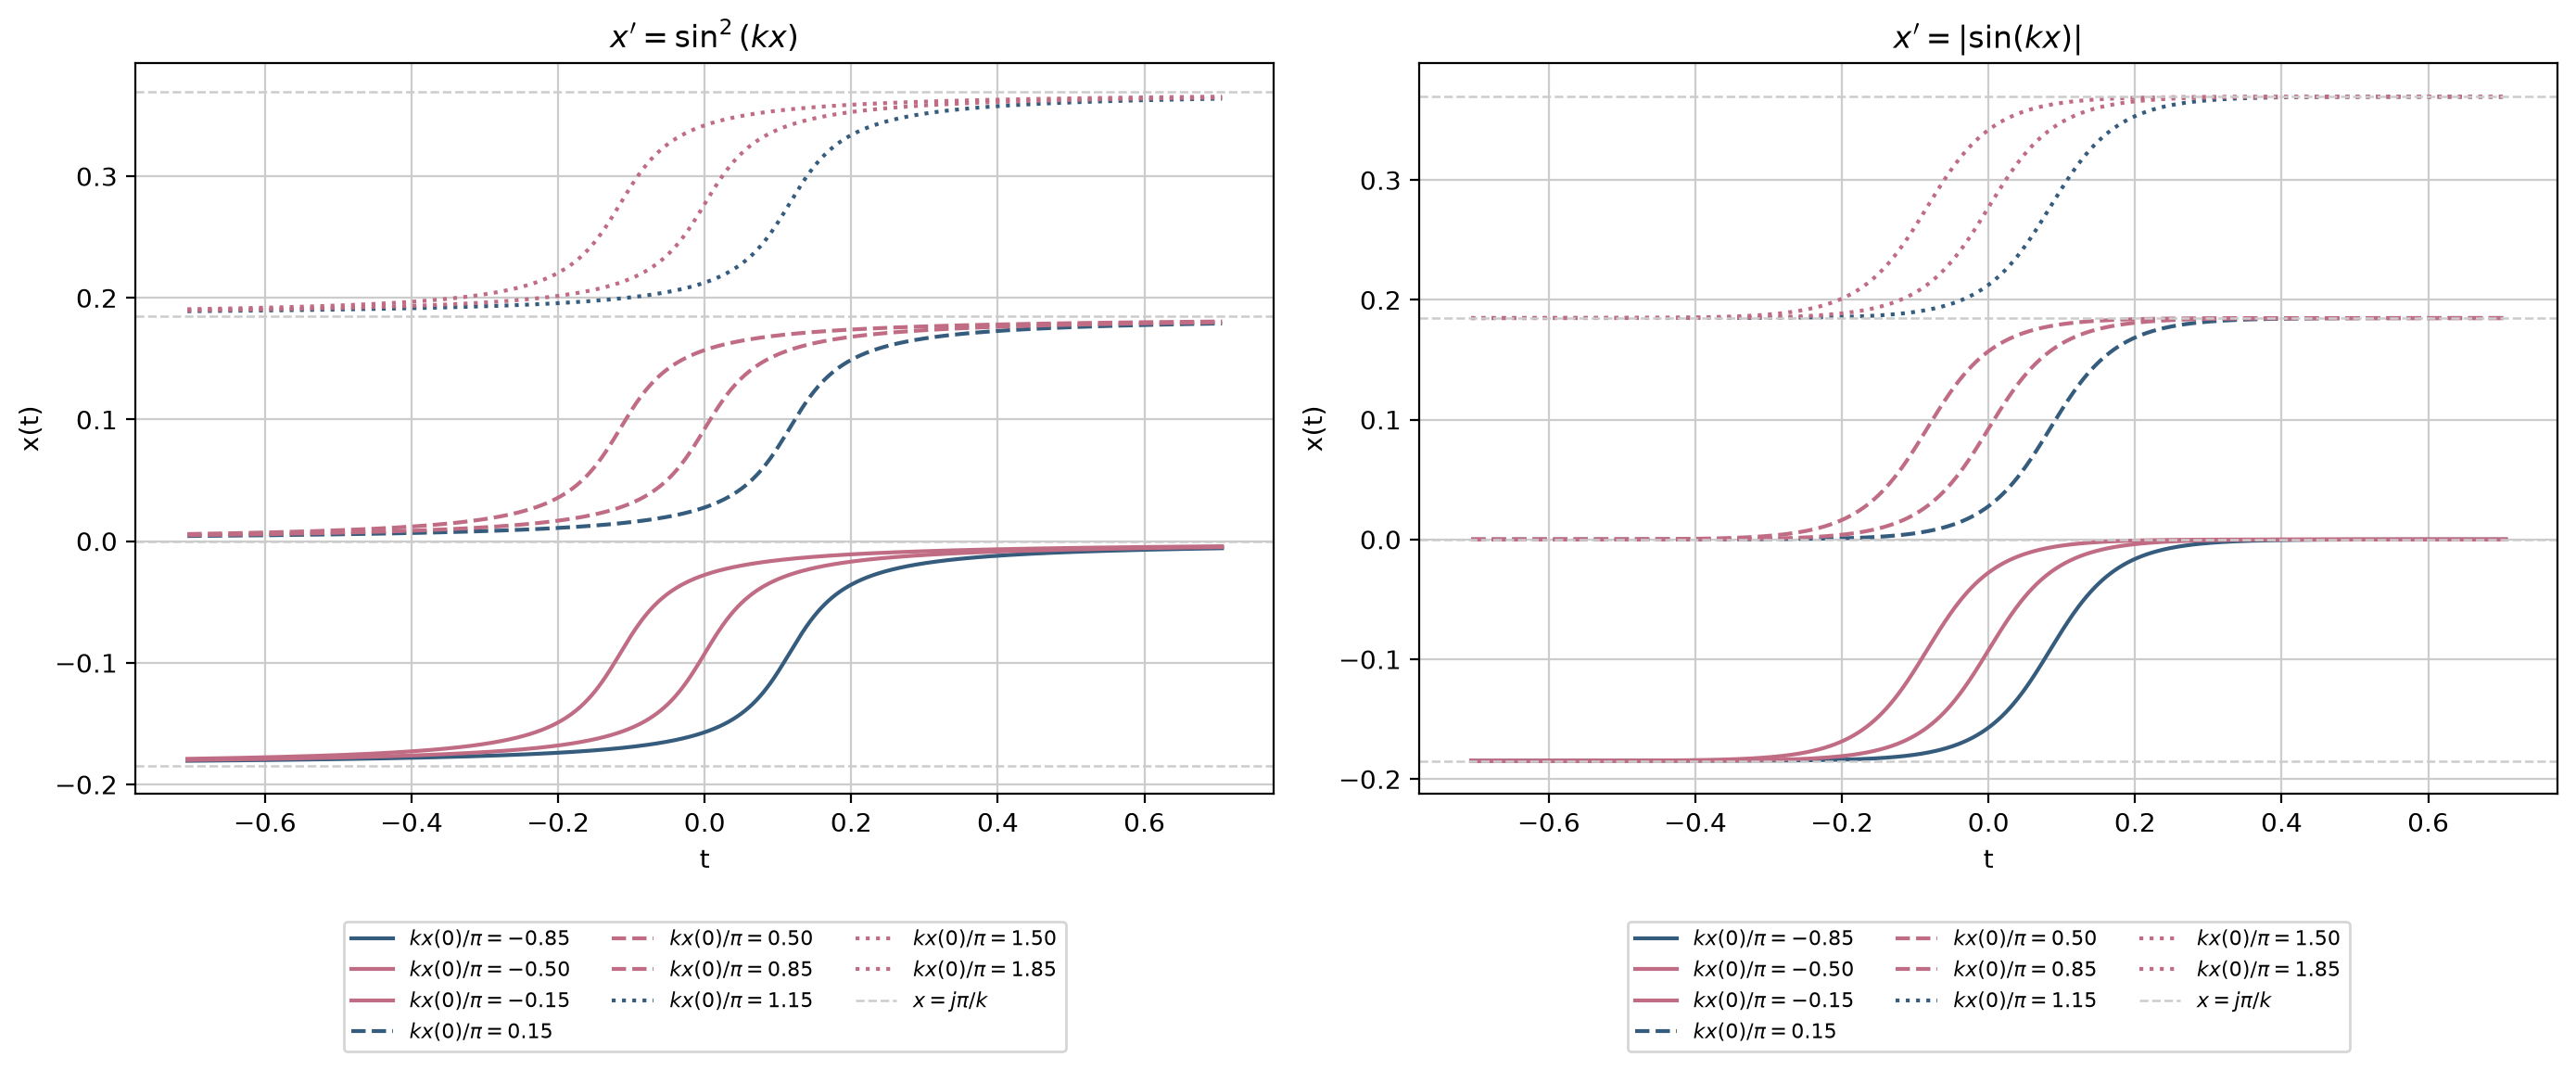

In [11]:
tau = np.linspace(-12, 12, 2401)
t = tau / k
initial_y = [j * np.pi + a * np.pi for j in [-1, 0, 1] for a in [0.15, 0.5, 0.85]]
line_styles = ['-', '--', ':']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

powers = [2, 1]
titles = [r"$x'=\sin^2(kx)$", r"$x'=|\sin(kx)|$"]

for ax, power, title in zip(axes, powers, titles):
    for index, y0 in enumerate(initial_y):
        x = regular_solution(tau, y0, power) / k
        ax.plot(
            t,
            x,
            color=maroon if index % 3 == 0 else red,
            ls=line_styles[index // 3],
            lw=1.5,
            label=fr'$kx(0)/\pi={y0 / np.pi:.2f}$',
        )

    for j in [-1, 0, 1, 2]:
        ax.axhline(j * np.pi / k, color=cream, lw=0.9, ls='--')

    ax.set(xlabel='t', ylabel='x(t)', title=title, facecolor=background)
    ax.grid(color=cream)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(
        handles + [equilibrium_handle],
        labels + [r'$x=j\pi/k$'],
        fontsize=8,
        ncol=3,
        loc='upper center',
        bbox_to_anchor=(0.5, -0.16),
    )

plt.tight_layout()
plt.show()

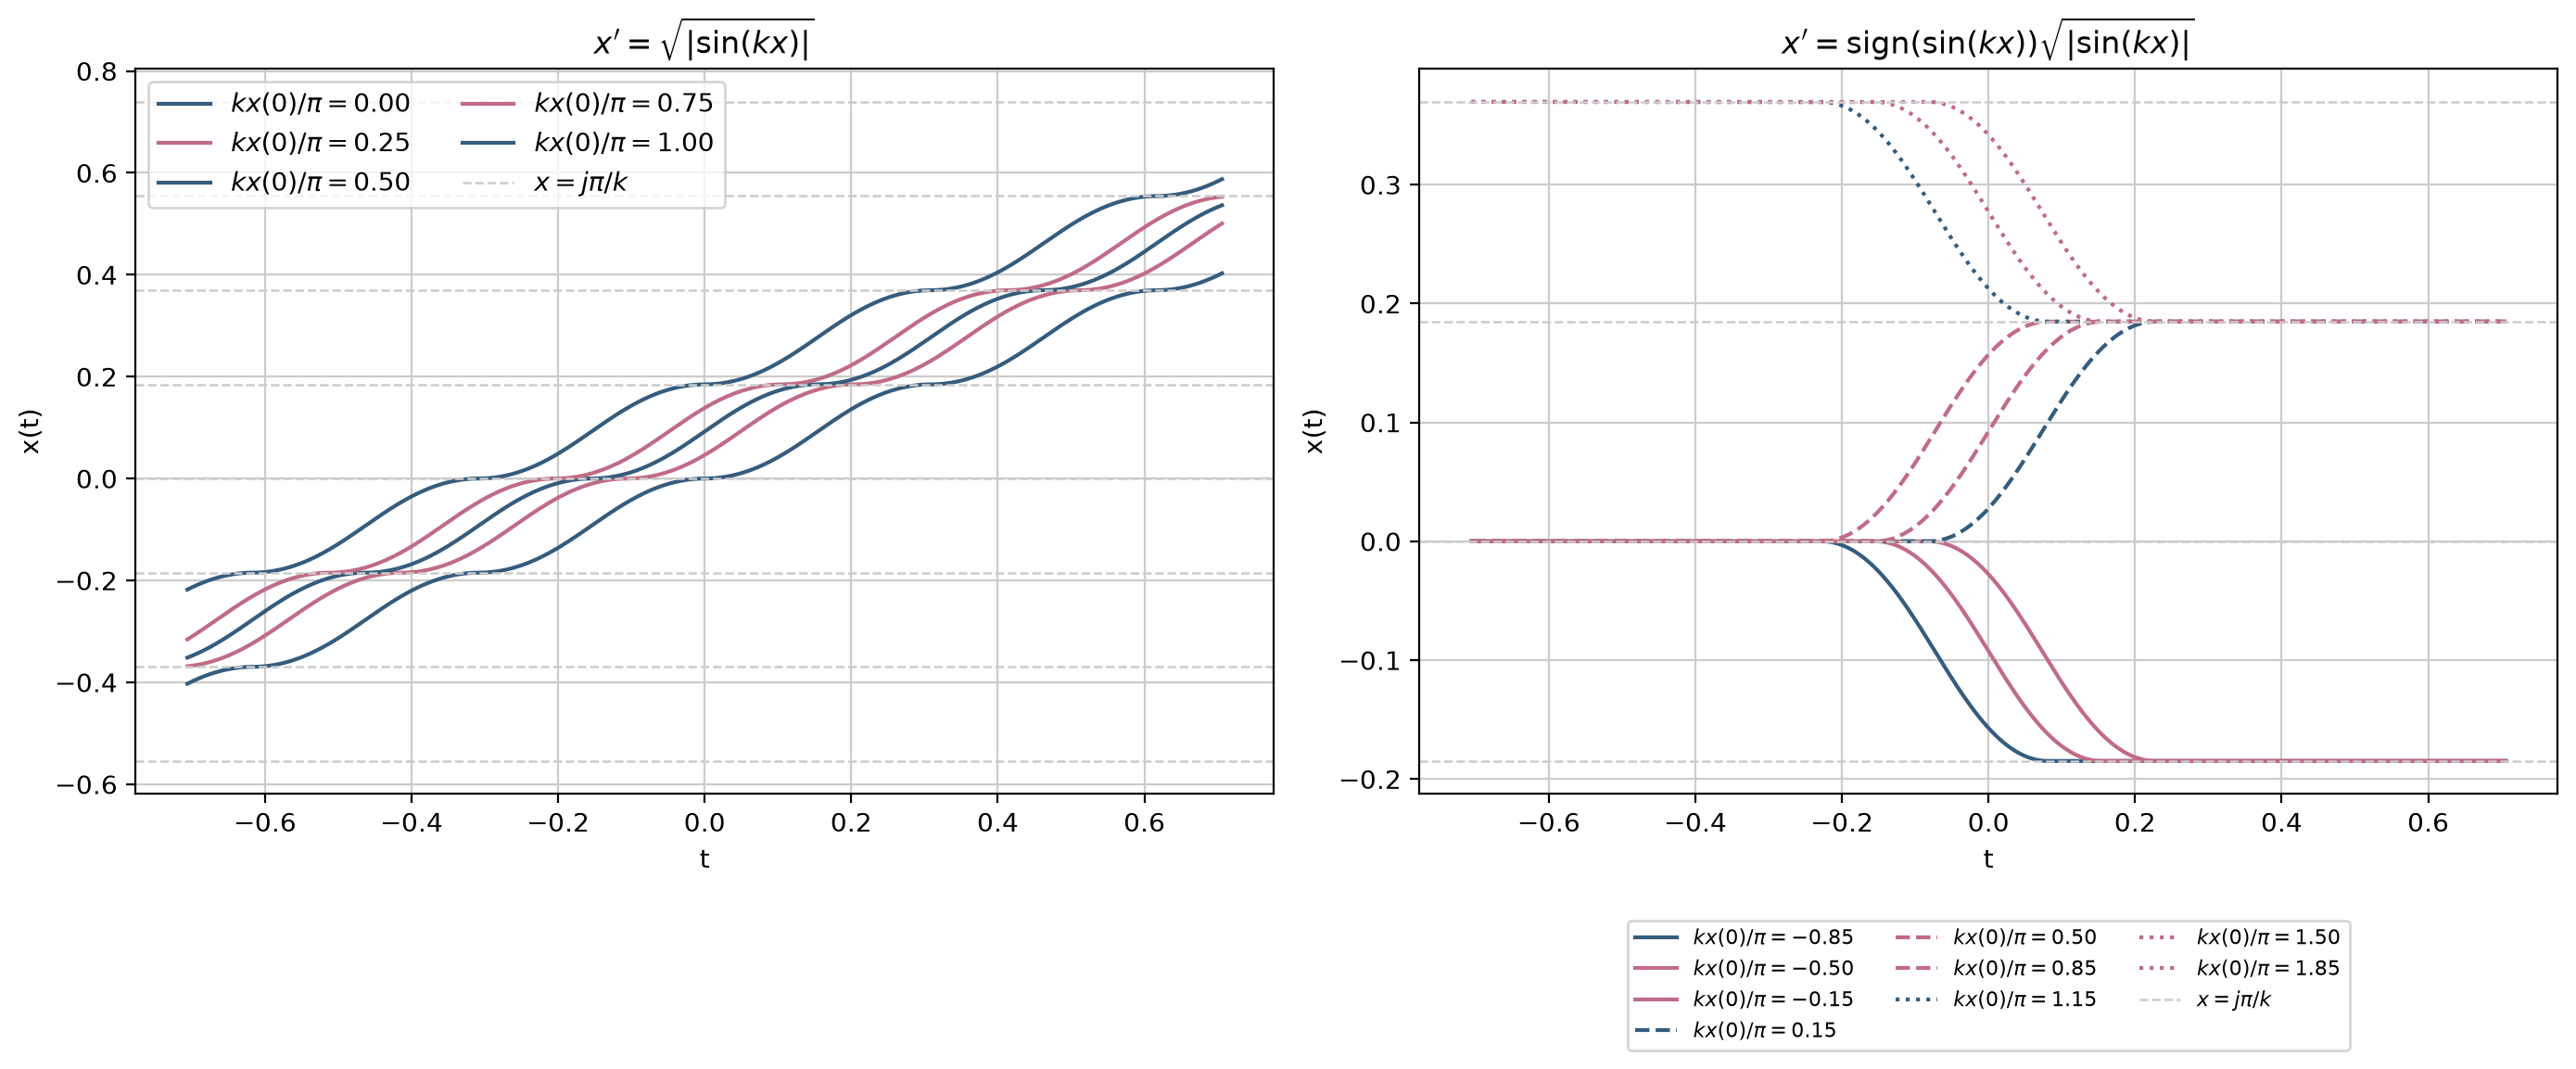

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for index, y0 in enumerate([0, np.pi / 4, np.pi / 2, 3 * np.pi / 4, np.pi]):
    axes[0].plot(
        t,
        sqrt_solution(tau, y0) / k,
        color=maroon if index % 2 == 0 else red,
        lw=1.5,
        label=fr'$kx(0)/\pi={y0 / np.pi:.2f}$',
    )

for j in range(-3, 5):
    axes[0].axhline(j * np.pi / k, color=cream, lw=0.9, ls='--')

axes[0].set(
    xlabel='t',
    ylabel='x(t)',
    title=r"$x'=\sqrt{|\sin(kx)|}$",
    facecolor=background,
)
axes[0].grid(color=cream)
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(handles + [equilibrium_handle], labels + [r'$x=j\pi/k$'], ncol=2)

for index, y0 in enumerate(initial_y):
    axes[1].plot(
        t,
        signed_sqrt_solution(tau, y0) / k,
        color=maroon if index % 3 == 0 else red,
        ls=line_styles[index // 3],
        lw=1.5,
        label=fr'$kx(0)/\pi={y0 / np.pi:.2f}$',
    )

for j in [-1, 0, 1, 2]:
    axes[1].axhline(j * np.pi / k, color=cream, lw=0.9, ls='--')

axes[1].set(
    xlabel='t',
    ylabel='x(t)',
    title=r"$x'=\operatorname{sign}(\sin(kx))\sqrt{|\sin(kx)|}$",
    facecolor=background,
)
axes[1].grid(color=cream)
handles, labels = axes[1].get_legend_handles_labels()
axes[1].legend(
    handles + [equilibrium_handle],
    labels + [r'$x=j\pi/k$'],
    fontsize=8,
    ncol=3,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.16),
)

plt.tight_layout()
plt.show()